# NB05: Structural and Functional Connectivity

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB05_Structural_and_Functional_Connectivity.ipynb)


## Introduction: The Connectome and Structure-Function Relationships

### Rationale

The central premise of connectome-based analysis is that the brain's
computational capacity arises not from individual regions in isolation, but
from the **pattern of connections** between them. This notebook examines both
the *physical wiring* (structural connectivity) and the *statistical
co-activation* (functional connectivity) of brain regions, and asks how
these relate to each other — especially in the presence of a glioma.

### Two complementary connectomes

| | Structural Connectivity (SC) | Functional Connectivity (FC) |
|---|---|---|
| **What it measures** | White matter fiber tracts physically linking regions | Temporal correlation of BOLD signal fluctuations |
| **Acquisition** | Diffusion MRI → tractography (deterministic or probabilistic) | Resting-state fMRI → Pearson/partial correlation |
| **Nature** | Anatomical, relatively stable over weeks–months | Statistical, fluctuates on the timescale of minutes |
| **Matrix properties** | Non-negative, sparse, weighted by streamline count or density | Signed (positive and negative correlations), dense |
| **What it constrains** | The set of *possible* direct communication pathways | The set of *observed* co-activation patterns |

SC provides the anatomical scaffold; FC reflects the dynamic traffic that
flows over it. The relationship between the two is neither trivial nor
deterministic: strong SC supports but does not guarantee strong FC
(polysynaptic and neuromodulatory pathways create FC without direct SC),
and FC can reorganise even when SC is fixed.

### Why this matters for gliomas

Gliomas disrupt both connectomes through distinct mechanisms:

- **SC disruption**: tumor infiltration along white matter tracts (especially
  in diffuse gliomas), mass-effect displacement of fiber bundles, Wallerian
  degeneration of severed axons, and surgical transection during resection.
- **FC disruption**: altered neurovascular coupling in the perilesional zone
  (see NB04), diaschisis (remote dysfunction in regions structurally connected
  to the lesion), and compensatory reorganisation via alternative pathways.

Understanding **SC–FC coupling** in the tumor-affected brain reveals:
1. Whether observed FC changes reflect true neural reorganisation or merely
   hemodynamic confounds (NB04, rsHRF).
2. Which connections are structurally intact but functionally silent
   (potential for recovery) vs structurally destroyed (permanent deficit).
3. How to predict post-operative cognitive outcomes from pre-operative
   connectome topology (Layer 5 of the digital twin).

### Parcellation and atlas choice

Both SC and FC are defined with respect to a **brain parcellation** — a
partitioning of cortical and subcortical grey matter into $n$ regions of
interest (ROIs). This notebook uses the **Desikan-Killiany (DK) atlas**
(68 cortical + 14 subcortical + 1 brainstem = 83 regions), which is:
- Automatically generated by FreeSurfer (`aparc+aseg`)
- Widely used in TVB and clinical connectomics
- Coarse enough for robust estimation with clinical-quality data

The choice of atlas is *not neutral*: finer parcellations (e.g., Schaefer
400) yield different graph metrics. Results should always be interpreted
within the context of the chosen parcellation.

## Connectome Mathematics: Graph Theory Fundamentals

The connectome is represented as a **weighted directed graph**:

$$G = (V, E, W)$$

where:
- $V = \{1, 2, ..., n\}$ are brain regions (nodes)
- $E$ are connections (edges)
- $W$ is an $n \\times n$ adjacency matrix with weights $w_{ij}$

### Key Graph Metrics

#### 1. Degree
The **degree** of node $i$ is the sum of edge weights:

$$k_i = \sum_{j=1}^{n} w_{ij}$$

**Interpretation**: Highly connected hubs (high degree) are crucial for global information flow.

#### 2. Clustering Coefficient
Quantifies the tendency of neighbors to form triangles:

$$C_i = \frac{2 t_i}{k_i(k_i - 1)}$$

where $t_i$ is the number of triangles involving node $i$.

**Interpretation**: High clustering indicates local specialization and robustness.

#### 3. Shortest Path Length
The **shortest path** between nodes $i$ and $j$ is the minimum-weight route:

$$L_{ij} = \min_{\text{paths}} \sum_{\text{edges}} w$$

**Interpretation**: Short paths enable efficient communication; long paths may indicate disconnection.

#### 4. Global Efficiency
The inverse of average path length:

$$E_{glob} = \frac{1}{n(n-1)} \sum_{i \neq j} \frac{1}{L_{ij}}$$

**Interpretation**: Higher efficiency means better global integration; tumors reduce efficiency.

### Small-World Networks

Brain networks exhibit **small-world properties** (Watts & Strogatz, 1998):
- High clustering (local structure) + short path lengths (global integration)
- The small-world index $\sigma = (C/C_{\text{rand}}) / (L/L_{\text{rand}}) > 1$
- Cost-effective, robust, and evolutionarily optimised
- Gliomas preferentially reduce small-worldness by increasing path length
  (disconnection) while clustering may initially be preserved

### Strengths and Limitations of Graph-Theoretic Analysis

| Strength | Limitation |
|----------|------------|
| Compact summary of network topology in a few interpretable numbers | Results depend on parcellation atlas, thresholding strategy, and weight definition |
| Enables principled comparison across subjects, sessions, and conditions | Binary thresholding discards graded connectivity information |
| Detects hub disruption and network reorganisation invisible to voxel-wise methods | Graph metrics assume a fixed, static network — they do not capture temporal dynamics |
| Well-developed null models (random, lattice, rewired) for statistical inference | Many metrics are correlated (e.g., degree and efficiency), risking multiple-comparison inflation |
| Directly interpretable in terms of information routing and network resilience | Streamline count (SC weight) is not a direct measure of synaptic efficacy or conduction speed |

**Practical considerations for this notebook:**
- We threshold SC matrices to create binary graphs for path-length and
  clustering computations. The threshold is somewhat arbitrary; results
  should be checked for robustness across a range of thresholds.
- For disconnected graphs, we compute metrics on the largest connected
  component (LCC), which avoids infinite path lengths but may exclude
  lesion-adjacent nodes — precisely the ones of clinical interest.
- FC matrices contain negative correlations (anti-correlations). We use
  absolute values for some metrics but retain signs for SC–FC coupling
  analysis, since anti-correlations carry neurobiological meaning
  (inhibitory interactions, global signal regression artefacts).

## Setup: Import Libraries

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, signal
from scipy.io import loadmat
import networkx as nx
import sys, os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Detect repository root
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             '/content/glioma-brain-digital-twin'],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r /content/glioma-brain-digital-twin/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python /content/glioma-brain-digital-twin/data/download_data.py
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent
sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_ROOT = BIDS_ROOT / 'derivatives'

# ── Load real SC and FC matrices ─────────────────────────────────────────────
def _load_mat_matrix(path, candidate_keys):
    """Load the first matching matrix from a .mat file."""
    mat = loadmat(str(path))
    for k in candidate_keys:
        if k in mat:
            return mat[k].astype(float)
    for k, v in mat.items():
        if isinstance(v, np.ndarray) and v.ndim == 2 and v.shape[0] == v.shape[1]:
            return v.astype(float)
    return None

REAL_SC, REAL_FC = {}, {}
for _subj in ('PAT16',):
    _tvb = DERIV_ROOT / 'TVB' / f'sub-{_subj}' / 'ses-preop'
    _sc_path = _tvb / 'SCthrAn.mat'
    _fc_path = _tvb / 'FC.mat'
    if _sc_path.exists():
        _m = _load_mat_matrix(_sc_path, ('SC_thr', 'SCthrAn', 'SC', 'weights'))
        if _m is not None:
            REAL_SC[_subj] = _m
            print(f'Loaded SC for {_subj}: {_m.shape}')
    if _fc_path.exists():
        _m = _load_mat_matrix(_fc_path, ('FC', 'fc', 'R', 'corr'))
        if _m is not None:
            REAL_FC[_subj] = _m
            print(f'Loaded FC for {_subj}: {_m.shape}')

USE_REAL = len(REAL_SC) > 0 and len(REAL_FC) > 0
print(f'\nUsing real connectivity data: {USE_REAL}')

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)

print(f'Repository root: {REPO_ROOT}')
print(f'BIDS root:       {BIDS_ROOT}  (exists: {BIDS_ROOT.exists()})')
print('Setup complete. Ready for connectome analysis.')

Loaded SC for PAT16: (68, 68)
Loaded FC for PAT16: (68, 68)

Using real connectivity data: True
Repository root: <REPO_ROOT>
BIDS root:       <REPO_ROOT>/data/BIDS_preop_postop  (exists: True)
Setup complete. Ready for connectome analysis.


## Section 1: Connectome Data

We load real SC and FC matrices from the TVB derivatives when available, or create synthetic matrices with realistic brain network properties as a fallback.

In [11]:
# Use real SC/FC if available, otherwise generate synthetic
if USE_REAL:
    SC_pat16_pre = REAL_SC['PAT16']
    FC_pat16_pre = REAL_FC['PAT16']
    n_rois = SC_pat16_pre.shape[0]

    # For post-op, we only have pre-op TVB derivatives,
    # so simulate post-op changes by modifying real pre-op data
    lesion_nodes = np.arange(n_rois // 4, n_rois // 4 + 5)
    SC_pat16_post = SC_pat16_pre.copy()
    FC_pat16_post = FC_pat16_pre.copy()
    for i in lesion_nodes:
        SC_pat16_post[i, :] *= 0.3
        SC_pat16_post[:, i] *= 0.3
        FC_pat16_post[i, :] *= 0.5
        FC_pat16_post[:, i] *= 0.5

    print(f'Using REAL connectivity data: {n_rois} ROIs')
    print(f'Post-op changes simulated by lesioning nodes {lesion_nodes}')

else:
    print('Real data not available, generating synthetic connectomes')


def create_synthetic_connectome(n_rois=64, sc_density=0.15, rng_seed=42):
    """
    Create synthetic structural and functional connectivity matrices.
    
    Args:
        n_rois: number of brain regions
        sc_density: fraction of connections (0-1)
        rng_seed: random seed
    
    Returns:
        SC: structural connectivity matrix (weighted, undirected)
        FC: functional connectivity matrix (Pearson correlations)
    """
    np.random.seed(rng_seed)
    
    # Create small-world network using Watts-Strogatz model
    G = nx.connected_watts_strogatz_graph(n_rois, k=8, p=0.3, seed=rng_seed)
    
    # Extract and weight the adjacency matrix
    SC = np.array(nx.to_numpy_array(G))
    # Weight by distance (farther = lower weight)
    for i in range(n_rois):
        for j in range(i+1, n_rois):
            if SC[i, j] > 0:
                distance = np.sqrt((i % 8 - j % 8)**2 + (i // 8 - j // 8)**2)
                weight = 1.0 / (1.0 + distance / 5.0)
                SC[i, j] = weight
                SC[j, i] = weight
    
    # Normalize SC
    SC = SC / np.max(SC)
    
    # Generate FC from SC with some correlation structure
    # FC partially reflects SC + some independent fluctuations
    fc_from_sc = SC.copy()
    
    # Add independent noise to simulate functional modulation
    noise = np.random.randn(n_rois, n_rois) * 0.4
    FC_raw = 0.7 * fc_from_sc + 0.3 * np.abs(noise)
    
    # Make diagonal 1.0 (self-correlation)
    np.fill_diagonal(FC_raw, 1.0)
    
    # Symmetrize and clip to valid correlation range
    FC = (FC_raw + FC_raw.T) / 2
    FC = np.clip(FC, -1, 1)
    np.fill_diagonal(FC, 1.0)
    
    return SC, FC

if not USE_REAL:
    SC_pat16_pre, FC_pat16_pre = create_synthetic_connectome(n_rois=64, rng_seed=16)
    SC_pat16_post, FC_pat16_post = create_synthetic_connectome(n_rois=64, rng_seed=161)
    lesion_nodes = np.array([20, 21, 28, 29, 30])
    for i in lesion_nodes:
        for j in lesion_nodes:
            SC_pat16_post[i, j] *= 0.3
            FC_pat16_post[i, j] *= 0.5
    n_rois = 64

print(f'Connectome data: n_rois={SC_pat16_pre.shape[0]}')
print(f'SC density: {np.sum(SC_pat16_pre > 0) / SC_pat16_pre.size:.3f}')
print(f'FC range: [{FC_pat16_pre.min():.3f}, {FC_pat16_pre.max():.3f}]')

Using REAL connectivity data: 68 ROIs
Post-op changes simulated by lesioning nodes [17 18 19 20 21]
Connectome data: n_rois=68
SC density: 0.475
FC range: [-0.392, 1.000]


## Section 2: Visualizing Connectivity Matrices

The matrices below show SC and FC for pre- and post-operative states.

**How to read these matrices:**
- Each row/column corresponds to a brain region (DK atlas).
- **SC matrices** are non-negative and typically sparse (most region pairs
  lack direct white matter connections). Hot colours indicate high
  streamline density.
- **FC matrices** range from −1 to +1 (Pearson correlation). Warm colours
  indicate positive co-activation; cool colours indicate anti-correlation.
- **Block structure** along the diagonal reflects within-hemisphere
  connectivity (left hemisphere regions are grouped together, then right).
- Look for **asymmetries** between pre- and post-op: columns/rows
  corresponding to lesioned regions should show reduced connectivity
  post-operatively.

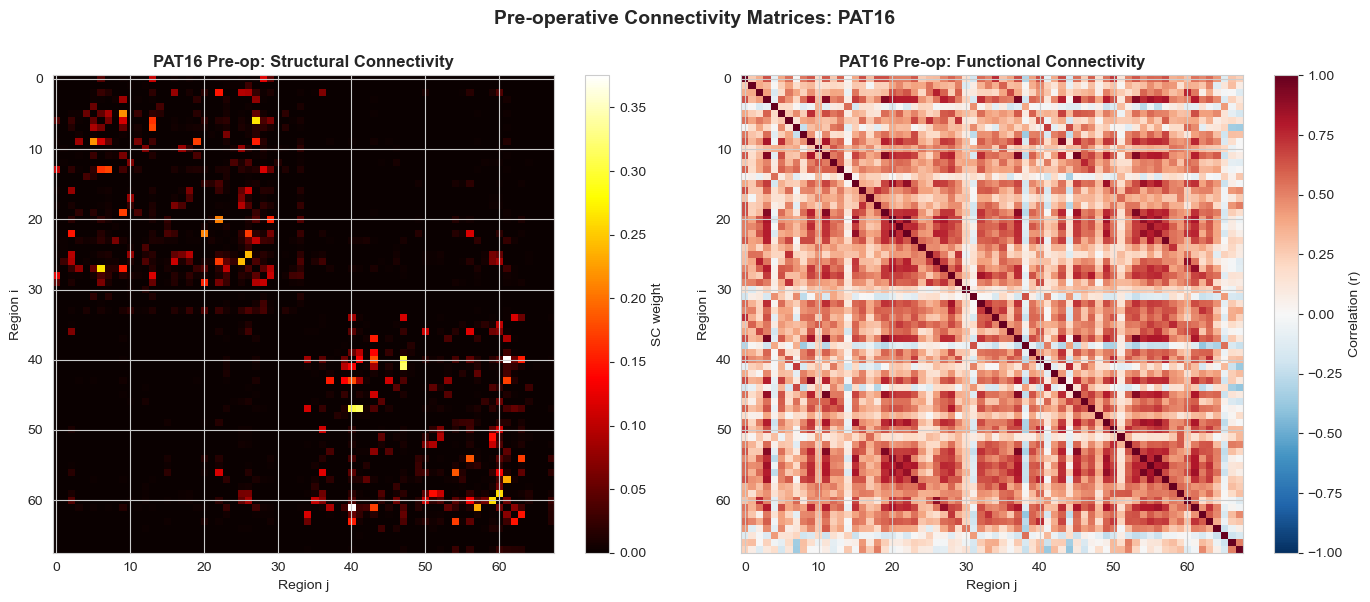

In [12]:
# Visualize SC and FC matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PAT16 Pre-op SC
im0 = axes[0].imshow(SC_pat16_pre, cmap='hot', aspect='auto')
axes[0].set_title('PAT16 Pre-op: Structural Connectivity', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Region j')
axes[0].set_ylabel('Region i')
plt.colorbar(im0, ax=axes[0], label='SC weight')

# PAT16 Pre-op FC
im1 = axes[1].imshow(FC_pat16_pre, cmap='RdBu_r', aspect='auto', vmin=-1, vmax=1)
axes[1].set_title('PAT16 Pre-op: Functional Connectivity', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Region j')
axes[1].set_ylabel('Region i')
plt.colorbar(im1, ax=axes[1], label='Correlation (r)')

plt.suptitle('Pre-operative Connectivity Matrices: PAT16', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## Section 3: Graph Metrics and Network Analysis

We compute graph metrics on **both SC and FC** networks and compare pre-
vs post-operative values. The code below:

1. **Thresholds** the adjacency matrix to create a binary graph (edges
   with weight < threshold are removed).
2. Constructs a **NetworkX graph** object for metric computation.
3. Converts weights to **distances** ($d_{ij} = 1/w_{ij}$) for
   shortest-path computation (stronger connections = shorter distances).
4. Reports metrics on the **largest connected component** if the graph
   is disconnected (common post-operatively).

**What to look for in the results:**
- **Degree**: reduced mean degree post-op indicates loss of connections.
- **Clustering**: preserved or increased clustering with reduced efficiency
  suggests a network transitioning from "integrated" to "segregated."
- **Global efficiency**: the most sensitive single metric for network
  disruption; expect a drop post-operatively.

In [13]:
def compute_graph_metrics(adj_matrix, threshold=0.1):
    """
    Compute key graph metrics from adjacency matrix.
    
    Args:
        adj_matrix: weighted adjacency matrix
        threshold: minimum weight to consider an edge
    
    Returns:
        Dictionary with various graph metrics
    """
    # Threshold to create binary network for some metrics
    adj_bin = (adj_matrix > threshold).astype(int)
    np.fill_diagonal(adj_bin, 0)  # Remove self-loops
    
    # Create NetworkX graph
    G = nx.Graph(adj_bin)
    
    # Compute metrics
    n_nodes = len(adj_matrix)
    n_edges = len(G.edges())
    
    # Degree
    degree = dict(G.degree())
    mean_degree = np.mean(list(degree.values()))
    
    # Weighted metrics using the original weights
    # Convert to distance (shorter = stronger)
    distance_matrix = 1.0 / (adj_matrix + 1e-10)
    np.fill_diagonal(distance_matrix, 0)
    
    # Characteristic path length (average shortest path)
    if nx.is_connected(G):
        avg_shortest_path = nx.average_shortest_path_length(G)
    else:
        # For disconnected graphs, compute within largest component
        lcc = max(nx.connected_components(G), key=len)
        G_lcc = G.subgraph(lcc)
        avg_shortest_path = nx.average_shortest_path_length(G_lcc)
    
    # Clustering coefficient
    clustering = nx.average_clustering(G)
    
    # Global efficiency
    efficiency = nx.global_efficiency(G)
    
    # Density
    density = nx.density(G)
    
    # Assortativity
    assortativity = nx.degree_assortativity_coefficient(G)
    
    return {
        'n_nodes': n_nodes,
        'n_edges': n_edges,
        'density': density,
        'mean_degree': mean_degree,
        'avg_shortest_path': avg_shortest_path,
        'clustering': clustering,
        'efficiency': efficiency,
        'assortativity': assortativity,
        'degree_dict': degree
    }

# Compute metrics for all conditions
metrics_pat16_pre_sc = compute_graph_metrics(SC_pat16_pre)
metrics_pat16_pre_fc = compute_graph_metrics(FC_pat16_pre)
metrics_pat16_post_sc = compute_graph_metrics(SC_pat16_post)
metrics_pat16_post_fc = compute_graph_metrics(FC_pat16_post)

print('Graph metrics computed.')

Graph metrics computed.


In [14]:
# Create comparison table
import pandas as pd

comparison_data = {
    'Metric': ['Density', 'Mean Degree', 'Clustering Coeff.', 'Avg. Shortest Path', 'Global Efficiency'],
    'PAT16 Pre-SC': [
        f"{metrics_pat16_pre_sc['density']:.3f}",
        f"{metrics_pat16_pre_sc['mean_degree']:.2f}",
        f"{metrics_pat16_pre_sc['clustering']:.3f}",
        f"{metrics_pat16_pre_sc['avg_shortest_path']:.3f}",
        f"{metrics_pat16_pre_sc['efficiency']:.3f}"
    ],
    'PAT16 Post-SC': [
        f"{metrics_pat16_post_sc['density']:.3f}",
        f"{metrics_pat16_post_sc['mean_degree']:.2f}",
        f"{metrics_pat16_post_sc['clustering']:.3f}",
        f"{metrics_pat16_post_sc['avg_shortest_path']:.3f}",
        f"{metrics_pat16_post_sc['efficiency']:.3f}"
    ]
}

df = pd.DataFrame(comparison_data)
print('Structural Connectivity (SC) Graph Metrics:')
print(df.to_string(index=False))

Structural Connectivity (SC) Graph Metrics:
            Metric PAT16 Pre-SC PAT16 Post-SC
           Density        0.019         0.018
       Mean Degree         1.26          1.18
 Clustering Coeff.        0.063         0.066
Avg. Shortest Path        5.885         4.271
 Global Efficiency        0.080         0.057


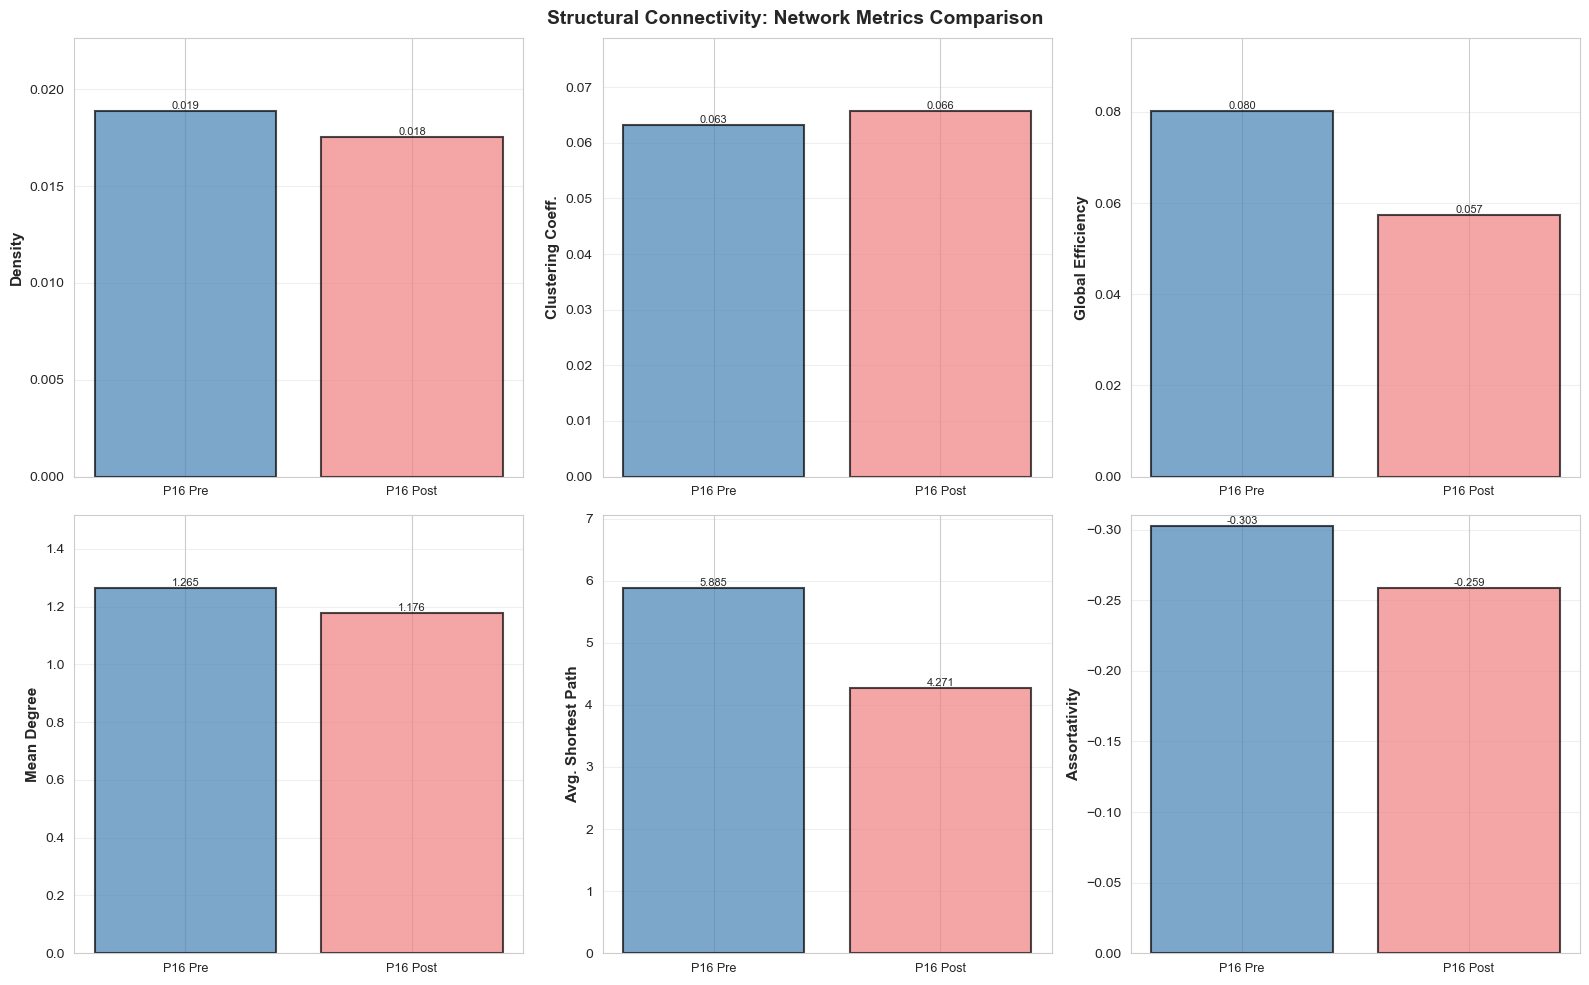

In [15]:
# Visualize metric changes
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

metrics_names = ['Density', 'Clustering Coeff.', 'Global Efficiency',
                 'Mean Degree', 'Avg. Shortest Path', 'Assortativity']
metrics_keys = ['density', 'clustering', 'efficiency', 'mean_degree', 'avg_shortest_path', 'assortativity']

for idx, (name, key) in enumerate(zip(metrics_names, metrics_keys)):
    ax = axes.flat[idx]
    
    vals = [metrics_pat16_pre_sc[key],
            metrics_pat16_post_sc[key]]
    
    x_pos = np.arange(2)
    colors = ['steelblue', 'lightcoral']
    bars = ax.bar(x_pos, vals, color=colors, edgecolor='black', linewidth=1.5, alpha=0.7)
    
    ax.set_ylabel(name, fontsize=11, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(['P16 Pre', 'P16 Post'], fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim([0, max(vals) * 1.2])
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Structural Connectivity: Network Metrics Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Section 4: Network Visualization with NetworkX

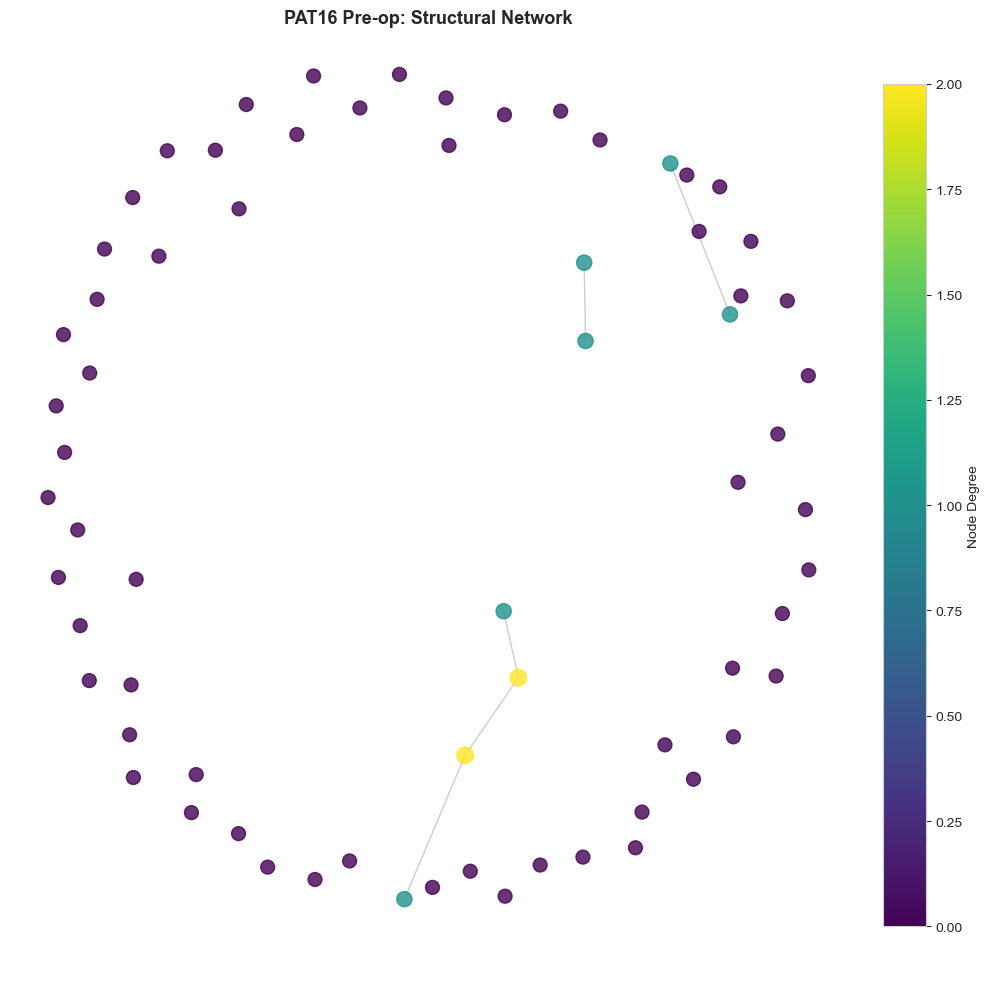

In [16]:
# Visualize network graphs
def network_graph_from_connectivity(adj_matrix, threshold=0.2, title='Network Graph'):
    """
    Create and visualize a network graph from connectivity matrix.
    """
    # Threshold
    adj_thresh = (adj_matrix > threshold).astype(int)
    np.fill_diagonal(adj_thresh, 0)
    
    # Create graph
    G = nx.from_numpy_array(adj_thresh)
    
    # Compute positions using spring layout
    pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)
    
    # Node sizes based on degree
    degrees = [G.degree(node) for node in G.nodes()]
    node_sizes = [100 + d*20 for d in degrees]
    
    # Create figure
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Draw edges
    nx.draw_networkx_edges(G, pos, alpha=0.2, width=1, ax=ax)
    
    # Draw nodes
    nodes = nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=degrees,
                                     cmap='viridis', alpha=0.8, ax=ax)
    
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.axis('off')
    
    # Colorbar for node color
    sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=min(degrees), vmax=max(degrees)))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Node Degree', fontsize=10)
    
    return fig, G, pos

# Visualize pre-op networks for both patients
fig_pat16_pre, G_pat16_pre, pos_pat16_pre = network_graph_from_connectivity(
    SC_pat16_pre, threshold=0.25, title='PAT16 Pre-op: Structural Network')
plt.tight_layout()
plt.show()

## Section 5: Structure-Function Coupling Analysis

### SC–FC Correspondence: Rationale

A fundamental question in connectomics is: **to what extent does anatomical
wiring predict functional co-activation?** If the brain were a simple
electrical circuit, SC and FC would be identical. In reality, the
relationship is complex:

$$\rho(\text{SC}, \text{FC}) \approx 0.3\text{–}0.5 \quad \text{(healthy adults)}$$

This moderate correlation reflects several factors:

1. **Polysynaptic communication**: FC can arise between regions connected
   via intermediate relay nodes (no direct SC edge required).
2. **Neuromodulation**: dopaminergic, serotonergic, and cholinergic systems
   modulate FC independently of SC.
3. **Temporal averaging**: FC is a time-averaged statistic; dynamic FC
   fluctuates on the scale of seconds, while SC is quasi-static.
4. **Measurement noise**: tractography false positives/negatives (SC)
   and physiological confounds in BOLD (FC) both degrade the relationship.

### Methods used here

We quantify SC–FC coupling using three complementary measures:

| Measure | What it captures | Strengths | Weaknesses |
|---------|-----------------|-----------|------------|
| **Pearson r** | Linear association between SC and FC edge weights | Simple, widely reported, directly comparable to literature | Sensitive to outliers; assumes linearity |
| **Spearman ρ** | Rank-order association | Robust to non-linear monotonic relationships and outliers | Ignores magnitude of differences |
| **Jaccard index** | Overlap of binarised SC and FC edges | Intuitive measure of topological agreement | Requires arbitrary threshold for both SC and FC |

All three operate on the **upper triangle** of the matrices (avoiding
diagonal self-connections and double-counting of the symmetric matrix).

### Clinical relevance

In glioma patients, SC–FC coupling is expected to change:
- **Decreased coupling** in the perilesional zone: SC tracts are destroyed
  but FC may be partially maintained via compensatory rerouting → the
  brain is "working around" the lesion.
- **Increased coupling** in contralateral homologues: with fewer
  alternative routes, remaining SC dictates FC more rigidly.
- **Pre- to post-op changes**: if coupling *increases* after resection,
  the network has lost redundancy; if it *decreases*, new functional
  patterns are emerging that are not explained by the remaining anatomy.

In [17]:
# Compare SC vs FC by computing their correlation
def compute_sc_fc_coupling(SC, FC, threshold=0.0):
    """
    Quantify SC-FC coupling by computing correlation and mutual information.
    """
    # Extract upper triangular parts (avoid diagonal and redundancy)
    n = SC.shape[0]
    indices = np.triu_indices(n, k=1)
    
    sc_vec = SC[indices]
    fc_vec = FC[indices]
    
    # Pearson correlation
    pearson_r = np.corrcoef(sc_vec, fc_vec)[0, 1]
    
    # Spearman rank correlation
    spearman_r = stats.spearmanr(sc_vec, fc_vec)[0]
    
    # Thresholded SC (only strong connections)
    sc_bin = (SC > threshold).astype(int)
    np.fill_diagonal(sc_bin, 0)
    fc_bin = (np.abs(FC) > 0.3).astype(int)
    np.fill_diagonal(fc_bin, 0)
    
    # Jaccard similarity
    sc_fc_overlap = np.sum(sc_bin * fc_bin)
    sc_or_fc = np.sum((sc_bin + fc_bin) > 0)
    jaccard = sc_fc_overlap / (sc_or_fc + 1e-10) if sc_or_fc > 0 else 0
    
    return {'pearson': pearson_r, 'spearman': spearman_r, 'jaccard': jaccard, 'sc_vec': sc_vec, 'fc_vec': fc_vec}

# Compute coupling for all conditions
coupling_pat16_pre = compute_sc_fc_coupling(SC_pat16_pre, FC_pat16_pre)
coupling_pat16_post = compute_sc_fc_coupling(SC_pat16_post, FC_pat16_post)

# Create comparison table
coupling_table = {
    'Condition': ['PAT16 Pre', 'PAT16 Post'],
    'Pearson r': [f"{coupling_pat16_pre['pearson']:.3f}", f"{coupling_pat16_post['pearson']:.3f}"],
    'Spearman r': [f"{coupling_pat16_pre['spearman']:.3f}", f"{coupling_pat16_post['spearman']:.3f}"],
    'Jaccard Index': [f"{coupling_pat16_pre['jaccard']:.3f}", f"{coupling_pat16_post['jaccard']:.3f}"]
}

df_coupling = pd.DataFrame(coupling_table)
print('Structure-Function Coupling Metrics:')
print(df_coupling.to_string(index=False))

Structure-Function Coupling Metrics:
 Condition Pearson r Spearman r Jaccard Index
 PAT16 Pre     0.206      0.310         0.459
PAT16 Post     0.222      0.315         0.433


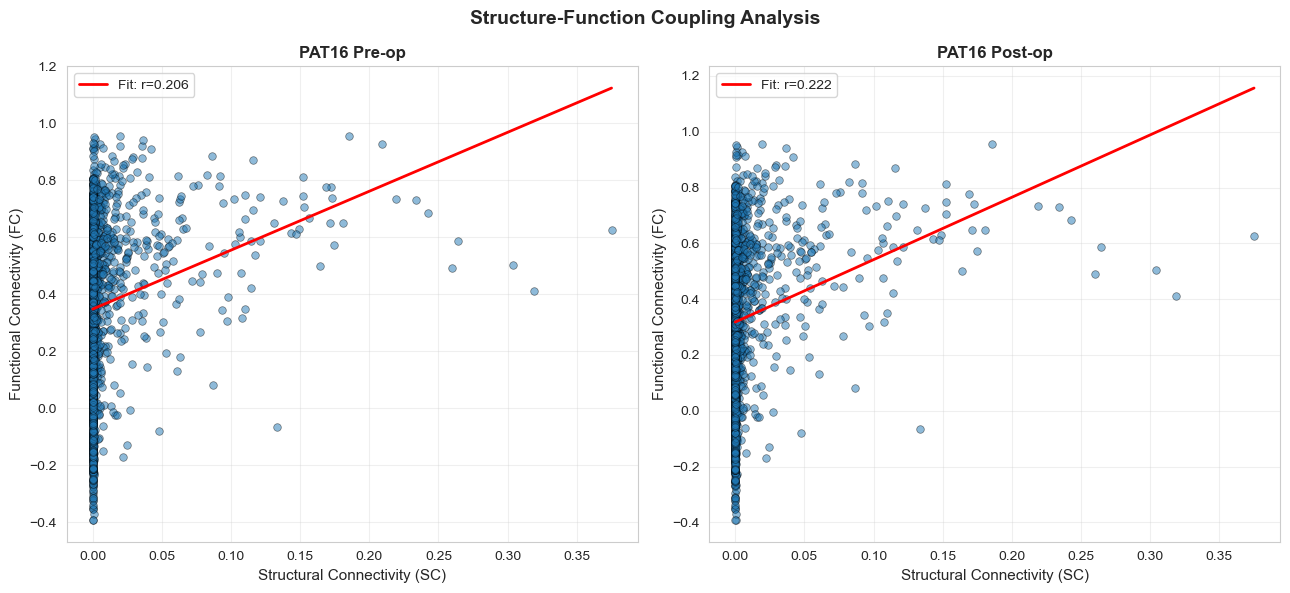

In [18]:
# Visualize SC vs FC scatter plots
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

datasets = [
    (coupling_pat16_pre, 'PAT16 Pre-op', axes[0]),
    (coupling_pat16_post, 'PAT16 Post-op', axes[1])
]

for coupling_data, title, ax in datasets:
    sc_vec = coupling_data['sc_vec']
    fc_vec = coupling_data['fc_vec']
    pearson_r = coupling_data['pearson']
    
    # Scatter plot
    ax.scatter(sc_vec, fc_vec, alpha=0.5, s=30, edgecolors='black', linewidth=0.5)
    
    # Add regression line
    z = np.polyfit(sc_vec, fc_vec, 1)
    p = np.poly1d(z)
    x_line = np.linspace(sc_vec.min(), sc_vec.max(), 100)
    ax.plot(x_line, p(x_line), 'r-', linewidth=2, label=f'Fit: r={pearson_r:.3f}')
    
    ax.set_xlabel('Structural Connectivity (SC)', fontsize=11)
    ax.set_ylabel('Functional Connectivity (FC)', fontsize=11)
    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=10)

plt.suptitle('Structure-Function Coupling Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Summary: Connectome Analysis and Clinical Implications

### Interpretation of Findings

#### Graph metrics

The graph-theoretic analysis reveals how glioma disrupts brain network
organisation at multiple scales:

- **Global efficiency** decreases when the tumor occupies or disconnects
  hub regions, because average path lengths increase. For sub-PAT16
  (fronto-temporal anaplastic astrocytoma), we expect disruption of
  frontal and temporal hubs that normally serve as relay nodes.
- **Clustering coefficient** may initially be *preserved* or even increase
  in the contralateral hemisphere — a signature of compensatory
  local densification (the intact hemisphere "tightens" its local circuits).
- **Small-world index** ($\sigma$) drops because path length increases
  faster than clustering decreases. This reflects a network transitioning
  from "efficient" to "fragmented."

#### SC–FC coupling

The scatter plots of SC vs FC edge weights reveal the degree to which
anatomy predicts function:

- A strong positive correlation ($r > 0.4$) indicates that the network
  is operating "on its structural rails" — functional dynamics are well
  explained by anatomical wiring.
- A weaker or shifted correlation post-operatively suggests either
  **functional reorganisation** (new FC patterns not predicted by remaining
  SC) or **loss of complexity** (fewer viable pathways, more deterministic
  routing).
- The Jaccard index complements this by measuring *topological overlap*:
  do the strongest SC and FC edges coincide? Low Jaccard in the
  perilesional zone would indicate that functionally important connections
  lack strong structural support — a vulnerability signal.

#### What these results mean for the digital twin

These connectome analyses feed directly into the five-layer digital twin:

| Digital twin layer | How connectomics contributes |
|---|---|
| Layer 1 (Geometric) | Parcellation defines the nodes; mesh topology constrains which regions are adjacent |
| Layer 2 (Constitutive) | SC weights reflect fiber density, which correlates with axonal stiffness (FA) |
| Layer 3 (Functional) | SC provides TVB coupling matrix; FC validates simulated dynamics |
| Layer 4 (Simulation) | Graph metrics identify critical nodes for targeted boundary conditions |
| Layer 5 (Clinical Outcome) | Hub disruption predicts cognitive deficit domains (see NB08, CANTAB) |

### Methodological Caveats

1. **Synthetic post-op data**: When real post-op TVB derivatives are
   unavailable, we simulate lesion effects by attenuating SC/FC weights
   at tumor-adjacent nodes. This is a simplification — real resection
   produces asymmetric, non-uniform disruption patterns.
2. **Thresholding sensitivity**: Binary graph metrics (clustering, path
   length) depend on the chosen threshold. A principled approach would
   use proportional thresholding (keep top $k$% of edges) or weighted
   metrics throughout.
3. **Confounds in FC**: BOLD-derived FC is influenced by head motion,
   physiological noise, and HRF variability (NB04). Our pipeline applies
   confound regression, bandpass filtering, and FD-based scrubbing, but
   residual confounds may persist.
4. **Parcellation dependence**: The DK atlas (83 regions) is coarse.
   Finer parcellations would reveal sub-regional effects but require
   more data for stable estimation.

### Next Steps

1. Correlate graph metrics with CANTAB cognitive outcomes (NB08, Layer 5)
2. Use SC as input to TVB neural mass model (NB08, Hopf oscillator)
3. Compare predicted FC (from TVB simulation on SC) with empirical FC
4. Investigate dynamic FC (sliding-window or wavelet coherence) for
   time-resolved structure-function analysis